# Physical-risk losses and exposures

Catastrophe loss metrics, portfolio risk, and sector and country exposure datasets.

Run the notebook from top to bottom. Local section numbers are retained within each part.

1. [12g: Financial Loss and Catastrophe Metrics](#part-12g)
2. [12h: Sector and Corporate Physical-Risk Exposure](#part-12h)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from csaps import csaps

<a id="part-12g"></a>

## Part 1 — 12g: Financial Loss and Catastrophe Metrics

Converting catastrophe return periods to annual exceedance probabilities
and compounding them over multi-year horizons (a worked toy example),
real flood/landslide expected-loss-vs-time curves (Antofie et al.), the
ECB's 2022 economy-wide climate stress test's bank-portfolio
physical-risk-score and expected-loss tables, and Mandel et al.'s
regional climate capital-at-risk / value-at-risk tables.

**Data note (ECB physical-risk export):** the exported sheet has a
leading unnamed index column (`0, 1, 2, ...`) that shifts any
position-based column reference by one relative to the visible column
headers. To sidestep that trap entirely, columns are referenced by
**name** throughout rather than by position (names read directly off the
loaded `DataFrame`, cross-checked against the position arithmetic —
column 17 does land on `physcl_rsk_scr0_prcntg_ptfl`, confirming the
offset is exactly the leading index column and nothing else).

**Data note (Mandel regional tables):** the last section operates on an
11-column table that doesn't exist as a single sheet anywhere in the
shipped workbook — it's built by joining `Table 2` (6 columns) and
`Table 4` (6 columns) on the shared `Region` key, giving 11 columns.
Reproduced here with `pandas.merge`.


In [2]:
DATA_DIR = "../../data"

color_blue = "#1f77b4"
color_red = "#d62728"
color_green = "#2ca02c"

plt.rcParams["figure.dpi"] = 100

### 1. Return periods, exceedance probability, and multi-year loss compounding

A toy 5-event catastrophe table: return period $T$ (years) and expected
economic loss $E$ given the event occurs. Converts each return period to
an *annual exceedance probability* $p_T$, correcting for the
already-counted probability mass of more frequent (shorter-$T$) events at
each step — so $p_T$ answers "probability the event of return period $T$
or worse happens this year, given it wasn't already covered by a more
frequent event" — then compounds each $p_T$ over several multi-year
horizons $n$ and computes a probability-weighted expected loss
$\bar L(n) = \sum_T p_T(n)\cdot E_T$.


In [3]:
T = np.array([500, 200, 100, 50, 10], dtype=float)
E = np.array([720, 670, 628, 581, 434], dtype=float)
nT = len(T)

pe_T = 1 / T
p_T = np.zeros(nT)
p_T[0] = pe_T[0]
for i in range(1, nT):
    denom = np.prod(1 - p_T[:i])
    p_T[i] = 1 - (1 - pe_T[i]) / denom

results = pd.DataFrame(
    {"T (years)": T, "pe_T (%)": (100 * pe_T).round(3), "p_T (%)": (100 * p_T).round(3)}
)
display(results)

n = np.array([1, 2, 5, 10, 15, 25])
p_T_n = 1 - (1 - p_T[:, None]) ** n  # nT x len(n)
L_bar = (p_T_n * E[:, None]).sum(axis=0)
p_bar = 1 - np.prod(1 - p_T_n, axis=0)

multi_year = pd.DataFrame(
    100 * p_T_n, index=[f"T={int(t)}" for t in T], columns=[f"n={k}" for k in n]
)
multi_year.loc["p_bar (%)"] = 100 * p_bar
multi_year.loc["L_bar"] = L_bar
display(multi_year.round(3))

,T (years),pe_T (%),p_T (%)
0,500.0,0.2,0.200
1,200.0,0.5,0.301
2,100.0,1.0,0.503
3,50.0,2.0,1.010
4,10.0,10.0,8.163


,n=1,n=2,n=5,n=10,n=15,n=25
T=500,0.200,0.400,0.996,1.982,2.958,4.882
T=200,0.301,0.600,1.494,2.966,4.415,7.250
T=100,0.503,1.002,2.487,4.913,7.278,11.834
T=50,1.010,2.010,4.950,9.654,14.126,22.416
T=10,8.163,15.660,34.675,57.326,72.123,88.104
p_bar (%),10.000,19.000,40.951,65.132,79.411,92.821
L_bar,47.907,92.838,212.046,369.879,491.674,670.647


### 2. Flood and landslide expected-loss curves

Expected-loss-vs-time curves for river floods, coastal floods, and
landslides (Antofie et al.), smoothed with a weighted smoothing spline
(the endpoints — $n=0$ and the last observed horizon — are weighted 10x
heavier than interior points, so the curve is pinned close to $(0,0)$
and the final data point).


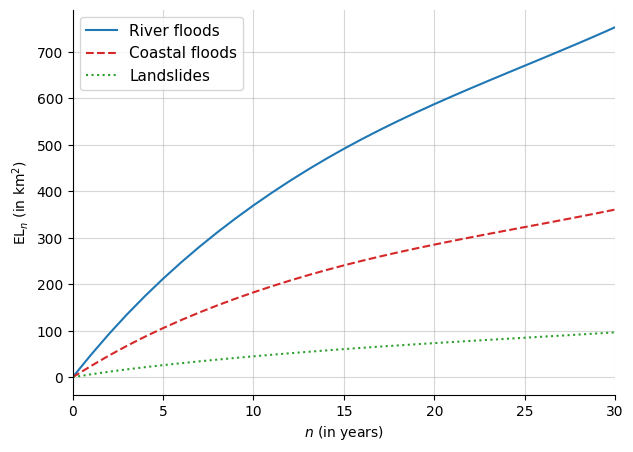

In [4]:
antofie = pd.read_excel(f"{DATA_DIR}/chap12_ext_antofie.xlsx", sheet_name="Data")
n_obs = np.concatenate([[0], antofie["n"].values]).astype(float)
EL_river = np.concatenate([[0], antofie["EL_river"].values])
EL_coastal = np.concatenate([[0], antofie["EL_coastal"].values])
EL_landslide = np.concatenate([[0], antofie["EL_landslide"].values])

x_grid = np.arange(0, 31)
weights = np.ones(len(n_obs))
weights[0] = 10
weights[-1] = 10

fig, ax = plt.subplots(figsize=(7, 5))
for y_obs, style, label, c in [
    (EL_river, "-", "River floods", color_blue),
    (EL_coastal, "--", "Coastal floods", color_red),
    (EL_landslide, ":", "Landslides", color_green),
]:
    y_smooth = csaps(n_obs, y_obs, x_grid, weights=weights, smooth=0.9)
    ax.plot(x_grid, y_smooth, style, color=c, linewidth=1.5, label=label)

ax.set_xlabel("$n$ (in years)")
ax.set_ylabel(r"$\mathrm{EL}_n$ (in km$^2$)")
ax.set_xlim(0, 30)
ax.legend(fontsize=11, loc="upper left")
ax.grid(True, alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

### 3-4. ECB physical-risk-score distribution by country/activity

Share of bank-loan portfolio value falling in each of 4 physical-risk
score tiers (0 = lowest, 3 = highest), by borrower country and economic
activity, for the ECB's 2022 climate stress test — historical drought-day
exposure vs. the same hazard projected under a high-emissions 2060
scenario. Both filter to portfolio-level rows only (no instrument-type or
creditor-sector breakdown — the two "all" filters below). Collapsed into
one parametrized helper called twice, since the two variants differ only
in the `hzrd_typ` filter string.


In [5]:
RS_COLS = [
    "physcl_rsk_scr0_prcntg_ptfl",
    "physcl_rsk_scr1_prcntg_ptfl",
    "physcl_rsk_scr2_prcntg_ptfl",
    "physcl_rsk_scr3_prcntg_ptfl",
]

ecb_rs = pd.read_excel(f"{DATA_DIR}/chap12_ext_ecb_physical_risk.xlsx", sheet_name="risk_scores")


def ecb_risk_score_table(hzrd_typ):
    T = ecb_rs[
        (ecb_rs["hzrd_typ"] == hzrd_typ)
        & (ecb_rs["stceg_instrmnt_typ"] == -1)
        & (ecb_rs["instttnl_sctr_crdtr_mrgd"] == -1)
    ].copy()
    T = T.dropna(subset=RS_COLS)
    T = T.sort_values(["crdtr_cntry", "stceg_ecnmc_actvty_name"])
    out = T[["crdtr_cntry", "stceg_ecnmc_actvty_name"] + RS_COLS].rename(
        columns={"crdtr_cntry": "Country", "stceg_ecnmc_actvty_name": "Activity"}
    )
    out[RS_COLS] = (100 * out[RS_COLS]).round(1)
    return out.reset_index(drop=True)


print("4a: historical drought-days exposure (ipcc_eu_CDD_v_hist_a)")
rs_hist = ecb_risk_score_table("ipcc_eu_CDD_v_hist_a")
display(rs_hist)

print("4b: projected 2060 RCP8.5 drought-days exposure (ipcc_eu_CDD_v_2060_r85_a)")
rs_2060 = ecb_risk_score_table("ipcc_eu_CDD_v_2060_r85_a")
display(rs_2060)

4a: historical drought-days exposure (ipcc_eu_CDD_v_hist_a)


,Country,Activity,physcl_rsk_scr0_prcntg_ptfl,physcl_rsk_scr1_prcntg_ptfl,physcl_rsk_scr2_prcntg_ptfl,physcl_rsk_scr3_prcntg_ptfl
0,AT,Total,7.9,44.4,47.3,0.4
1,DE,Total,2.0,93.7,4.1,0.3
2,ES,Total,0.6,20.8,55.2,23.4
3,FR,Total,1.3,79.7,17.7,1.3
4,IE,Total,18.3,70.1,10.5,1.1
5,IT,Total,0.4,11.6,81.7,6.3
6,LU,Total,8.2,78.5,11.8,1.4
7,PT,Total,0.3,6.2,29.0,64.5
8,U2,Construction,3.5,52.0,34.6,10.0
9,U2,Energy,0.7,63.1,28.5,7.7


4b: projected 2060 RCP8.5 drought-days exposure (ipcc_eu_CDD_v_2060_r85_a)


,Country,Activity,physcl_rsk_scr0_prcntg_ptfl,physcl_rsk_scr1_prcntg_ptfl,physcl_rsk_scr2_prcntg_ptfl,physcl_rsk_scr3_prcntg_ptfl
0,AT,Total,13.1,39.8,46.1,1.0
1,DE,Total,1.9,93.4,3.0,1.7
2,ES,Total,0.5,16.0,25.4,58.1
3,FR,Total,0.9,75.2,20.4,3.5
4,IE,Total,15.8,71.5,7.8,4.9
5,IT,Total,0.3,11.3,73.4,15.0
6,LU,Total,7.2,78.4,9.3,5.1
7,PT,Total,0.2,6.2,2.3,91.4
8,U2,Construction,2.3,51.6,27.5,18.5
9,U2,Energy,0.7,63.1,15.4,20.8


### 5-6. ECB expected-loss-at-maturity and annual expected loss

Coastal-flood expected loss (% of portfolio), both at loan maturity and
annualized, by country/activity — historical (1971-2000) vs. projected
end-of-century high-emissions (2071-2100 RCP8.5). Same collapsing
pattern as the risk-score tables above.


In [6]:
LOSS_COLS = [
    "physcl_rsk_near_mtrty_expctd_lss_prcntg_ptfl",
    "physcl_rsk_near_annl_expctd_lss_prcntg_ptfl",
]

ecb_loss = pd.read_excel(f"{DATA_DIR}/chap12_ext_ecb_physical_risk.xlsx", sheet_name="loss")


def ecb_loss_table(hzrd_typ):
    T = ecb_loss[ecb_loss["hzrd_typ"] == hzrd_typ].copy()
    T = T.dropna(subset=LOSS_COLS)
    T = T.sort_values(["crdtr_cntry", "stceg_ecnmc_actvty_name"])
    out = T[["crdtr_cntry", "stceg_ecnmc_actvty_name"] + LOSS_COLS].rename(
        columns={
            "crdtr_cntry": "Country",
            "stceg_ecnmc_actvty_name": "Activity",
            "physcl_rsk_near_mtrty_expctd_lss_prcntg_ptfl": "EL at maturity (%)",
            "physcl_rsk_near_annl_expctd_lss_prcntg_ptfl": "Annual EL (%)",
        }
    )
    out[["EL at maturity (%)", "Annual EL (%)"]] = (
        100 * out[["EL at maturity (%)", "Annual EL (%)"]]
    ).round(2)
    return out.reset_index(drop=True)


print("4c: historical coastal-flood exposure (ud_cf_1971_2000_hist)")
loss_hist = ecb_loss_table("ud_cf_1971_2000_hist")
display(loss_hist)

print("4d: projected 2071-2100 RCP8.5 coastal-flood exposure (ud_cf_2071_2100_RCP85)")
loss_2100 = ecb_loss_table("ud_cf_2071_2100_RCP85")
display(loss_2100)

4c: historical coastal-flood exposure (ud_cf_1971_2000_hist)


,Country,Activity,EL at maturity (%),Annual EL (%)
0,AT,Total,0.06,0.02
1,BE,Total,0.49,0.10
2,DE,Total,0.41,0.07
3,EE,Total,0.01,0.01
4,ES,Total,0.02,0.00
5,FI,Total,0.45,0.05
6,FR,Total,0.02,0.00
7,GR,Total,0.00,0.00
8,IE,Total,0.07,0.04
9,IT,Total,0.04,0.01


4d: projected 2071-2100 RCP8.5 coastal-flood exposure (ud_cf_2071_2100_RCP85)


,Country,Activity,EL at maturity (%),Annual EL (%)
0,AT,Total,0.09,0.03
1,BE,Total,0.55,0.11
2,DE,Total,0.48,0.08
3,EE,Total,0.01,0.01
4,ES,Total,0.04,0.01
5,FI,Total,0.42,0.04
6,FR,Total,0.03,0.01
7,GR,Total,0.01,0.00
8,HR,Total,0.00,0.00
9,IE,Total,0.10,0.05


### 7. Portfolio-level capital-at-risk / VaR multiplier

Mandel et al.'s global-portfolio climate-risk-adjusted returns: mean
expected loss and 99th-percentile loss (Q99, a tail/VaR-style measure)
for capital, bonds, and equity, across 3 warming scenarios, plus the
implied **tail multiplier** $\mathrm{Q99}/\mathrm{Mean}$ for each
asset class and scenario.


In [7]:
mandel_t1 = pd.read_excel(f"{DATA_DIR}/chap12_ext_mandel.xlsx", sheet_name="Table 1")
mandel_t1 = mandel_t1.sort_values("Statistic", kind="stable").reset_index(drop=True)
display(mandel_t1)

EL = mandel_t1[mandel_t1["Statistic"] == "Mean"][["Capital", "Bond", "Equity"]].reset_index(
    drop=True
)
VaR = mandel_t1[mandel_t1["Statistic"] == "Q99"][["Capital", "Bond", "Equity"]].reset_index(
    drop=True
)
multiplier = (VaR / EL).round(3)
multiplier.index = mandel_t1[mandel_t1["Statistic"] == "Mean"]["Scenario"].values
print("Q99 / Mean tail multiplier, by scenario:")
display(multiplier)

,Scenario,Statistic,Capital,Bond,Equity
0,RCP 2.6 2020,Mean,1.87,1.58,7.57
1,RCP 6.0 2050,Mean,2.22,2.36,10.69
2,RCP 8.5 2080,Mean,2.62,2.71,11.63
3,RCP 2.6 2020,Q99,3.34,4.29,10.57
4,RCP 6.0 2050,Q99,3.80,5.61,14.53
5,RCP 8.5 2080,Q99,4.32,6.41,15.90


Q99 / Mean tail multiplier, by scenario:


,Capital,Bond,Equity
RCP 2.6 2020,1.786,2.715,1.396
RCP 6.0 2050,1.712,2.377,1.359
RCP 8.5 2080,1.649,2.365,1.367


### 8. Regional impact and equity exposure

Mandel et al.'s regional climate-impact table, joined with a second
regional equity-market-exposure table on the shared `Region` key (the
join described above): for each region, its economic `Impact` (an
index), `Impact_ratio` (impact relative to global value share), and two
equity-exposure ratios (`Ratio1`, `Ratio2`).


In [8]:
mandel_t2 = pd.read_excel(f"{DATA_DIR}/chap12_ext_mandel.xlsx", sheet_name="Table 2")
mandel_t4 = pd.read_excel(f"{DATA_DIR}/chap12_ext_mandel.xlsx", sheet_name="Table 4")

joined = pd.merge(mandel_t2, mandel_t4, on="Region", how="inner")
joined = joined.sort_values("Region", kind="stable").reset_index(drop=True)
print(f"Joined table: {joined.shape[0]} regions x {joined.shape[1]} columns")

result = joined[
    ["Region", "Largest_contributor", "Impact", "Impact_ratio", "Ratio1", "Ratio2"]
].copy()
result[["Impact", "Impact_ratio", "Ratio1", "Ratio2"]] = result[
    ["Impact", "Impact_ratio", "Ratio1", "Ratio2"]
].round(2)
display(result)

Joined table: 13 regions x 11 columns


,Region,Largest_contributor,Impact,Impact_ratio,Ratio1,Ratio2
0,Australia and New Zealand,River flood,1.19,0.55,2.85,3.28
1,Eastern Asia,Tropical cyclone,3.59,1.66,0.76,0.89
2,Eastern Europe,River flood,0.70,0.33,5.72,3.34
3,Latin America,River flood,2.15,1.00,1.69,4.50
4,Northern Africa,River flood,2.13,0.99,0.16,0.30
5,Northern America,Tropical cyclone,1.30,0.60,1.03,0.77
6,Northern Europe,Winter storm,1.63,0.76,3.47,1.10
7,Southeastern Asia,Coastal flood,2.89,1.34,0.57,1.23
8,Southern Asia,River flood,3.84,1.78,0.59,0.88
9,Southern Europe,Winter storm,0.70,0.32,1.63,0.84


<a id="part-12h"></a>

## Part 2 — 12h: Sector and Corporate Physical-Risk Exposure

S&P's sector-level physical-risk exposure/sensitivity scores under
different climate scenarios, Cline (2007)'s classic agricultural
GDP-impact-by-country estimates, Munich Re's 45-year natural catastrophe
loss record, and the EIOPA insurance-risk dashboard's country x peril
climate risk scores.

**Data note:** the S&P workbook has a 3-row merged/nested Excel header
(scenario group label, then Exposure-Risk/Sensitivity-Risk sub-group,
then the actual `Sector`/`DM`/`EM` column names). The real header row is
picked out directly with `header=2` (0-indexed) on `pandas.read_excel`.


### 1. S&P 500 sector physical-risk exposure and sensitivity

Exposure-risk and sensitivity-risk scores (0-100 scale) by GICS sector,
separately for developed markets (DM) and emerging markets (EM), under 3
climate scenarios: Medium-warming 2030, Medium-warming 2050, and
High-warming 2050.


In [9]:
def load_snp_sheet(sheet):
    T = pd.read_excel(f"{DATA_DIR}/chap12_snp_physical_risk.xlsx", sheet_name=sheet, header=2)
    T.columns = [
        "Sector",
        "Weight_DM",
        "Weight_EM",
        "Exposure_DM",
        "Exposure_EM",
        "Sensitivity_DM",
        "Sensitivity_EM",
    ]
    return T


snp_med2030 = load_snp_sheet("Medium 2030")
snp_med2050 = load_snp_sheet("Medium 2050")
snp_high2050 = load_snp_sheet("High 2050")

sector = snp_med2030["Sector"]
exposure_sensitivity_cols = ["Exposure_DM", "Exposure_EM", "Sensitivity_DM", "Sensitivity_EM"]

combined = pd.concat(
    [
        snp_med2030[exposure_sensitivity_cols].add_prefix("Medium2030_"),
        snp_med2050[exposure_sensitivity_cols].add_prefix("Medium2050_"),
        snp_high2050[exposure_sensitivity_cols].add_prefix("High2050_"),
    ],
    axis=1,
)
combined.insert(0, "Sector", sector)
display(combined.round(1))

,Sector,Medium2030_Exposure_DM,Medium2030_Exposure_EM,Medium2030_Sensitivity_DM,Medium2030_Sensitivity_EM,Medium2050_Exposure_DM,Medium2050_Exposure_EM,Medium2050_Sensitivity_DM,Medium2050_Sensitivity_EM,High2050_Exposure_DM,High2050_Exposure_EM,High2050_Sensitivity_DM,High2050_Sensitivity_EM
0,Communication Services,57.9,57.3,20.1,18.9,63.3,64.3,23.5,21.9,67.8,68.5,26.1,24.1
1,Consumer Discretionary,56.5,62.0,32.9,33.1,62.3,67.4,37.3,37.4,66.9,71.7,41.4,41.1
2,Consumer Staples,57.3,60.7,31.6,42.9,63.1,66.3,35.9,47.9,68.0,70.9,39.8,52.2
3,Energy,57.5,62.9,35.7,47.1,62.7,68.1,39.8,51.7,67.4,72.3,43.5,55.5
4,Financials,57.1,62.5,14.4,19.9,63.1,67.8,16.4,23.3,67.8,72.1,18.3,26.3
5,Health Care,57.4,59.0,22.6,41.7,63.3,64.9,26.0,47.0,68.0,69.4,28.9,51.1
6,Industrials,56.7,59.6,30.3,39.0,62.7,65.3,34.6,43.9,67.5,70.1,38.4,48.4
7,Information Technology,58.2,61.4,17.6,43.2,64.1,66.5,20.4,47.7,68.9,71.5,23.3,52.5
8,Materials,59.5,64.4,43.4,52.9,65.2,69.8,48.2,57.9,69.8,74.0,52.2,61.8
9,Real Estate,54.9,64.5,33.3,42.3,61.1,69.9,38.1,47.0,65.8,73.8,42.3,51.0


### 2. Cline (2007) agricultural GDP impact, with and without carbon fertilization

Cline's classic estimate of projected long-run agricultural GDP impact by
country (% change), comparing a "without carbon fertilization" scenario
(ignoring CO2's direct growth-boosting effect on crops) against a "with
carbon fertilization" scenario. 76 countries/regions. (The workbook's
sheet name is capitalized `Data`, not `data` — a case mismatch was caught
and fixed while loading it.)


In [10]:
cline = pd.read_excel(f"{DATA_DIR}/chap12_ext_cline_2007.xlsx", sheet_name="Data")
country = cline["Regions"]
x = cline["Without_CF"]
y = cline["With_CF"]

for label, z in [
    ("Without carbon fertilization", x),
    ("With carbon fertilization", y),
    ("Difference (with - without)", y - x),
]:
    print(
        f"{label}: mean={z.mean():.2f}, min={z.min():.2f} ({country[z.idxmin()]}), max={z.max():.2f} ({country[z.idxmax()]})"
    )

n = len(country) // 2
table = pd.DataFrame(
    {
        "Region (1st half)": country.iloc[:n].values,
        "Without CF": x.iloc[:n].round(1).values,
        "With CF": y.iloc[:n].round(1).values,
        "Region (2nd half)": country.iloc[n:].values,
        "Without CF ": x.iloc[n:].round(1).values,
        "With CF ": y.iloc[n:].round(1).values,
    }
)
display(table)

Without carbon fertilization: mean=-17.64, min=-56.08 (Sudan), max=27.62 (USA North Central)
With carbon fertilization: mean=-5.28, min=-49.50 (Sudan), max=46.76 (USA North Central)
Difference (with - without): mean=12.35, min=6.59 (Sudan), max=19.14 (USA North Central)


,Region (1st half),Without CF,With CF,Region (2nd half),Without CF,With CF
0,Afghanistan,-24.7,-13.4,Morocco,-39.0,-29.9
1,Algeria,-36.0,-26.4,Nepal,-17.3,-4.8
2,Argentina,-11.1,2.2,Netherlands,-7.0,6.9
3,Australia,-26.6,-15.6,New Zealand,2.2,17.5
4,Australia Central East,-23.4,-11.9,Niger,-34.1,-24.2
5,Australia Central West,-35.1,-25.4,North Korea,-7.3,6.6
6,Australia North,-41.4,-32.6,Pakistan,-30.4,-20.0
7,Australia South East,-12.2,0.9,Peru,-30.6,-20.2
8,Australia South West,-13.5,-0.5,Philippines,-23.4,-11.9
9,Bangladesh,-21.7,-9.9,Poland,-4.7,9.5


### 3. Companion difference table

A small 4x4 table with no labels or surrounding context beyond generic
row/column data — plausibly a related illustrative comparison sitting
alongside the carbon-fertilization material above, but nothing ties down
what the rows/columns represent. Reproduced exactly as computed, without
inventing labels that aren't actually there.


In [11]:
data = np.array(
    [
        [4.9, 1.3, -6.4, -24.1],
        [5.0, 9.9, 8.8, 17.5],
        [6.5, 15.3, 2.0, -2.1],
        [7.7, 23.3, 3.4, 1.7],
    ]
)
print("Raw 4x4 table:")
display(pd.DataFrame(data, columns=["Col 1", "Col 2", "Col 3", "Col 4"]))

diff = np.column_stack([data[:, 2] - data[:, 0], data[:, 3] - data[:, 1]])
print("Difference table ([Col3 - Col1, Col4 - Col2]):")
display(pd.DataFrame(diff, columns=["Col3 - Col1", "Col4 - Col2"]))

Raw 4x4 table:


,Col 1,Col 2,Col 3,Col 4
0,4.9,1.3,-6.4,-24.1
1,5.0,9.9,8.8,17.5
2,6.5,15.3,2.0,-2.1
3,7.7,23.3,3.4,1.7


Difference table ([Col3 - Col1, Col4 - Col2]):


,Col3 - Col1,Col4 - Col2
0,-11.3,-25.4
1,3.8,7.6
2,-4.5,-17.4
3,-4.3,-21.6


### 4. Munich Re natural catastrophe losses, 1980-2024

45 years of global natural-catastrophe losses (Munich Re NatCatSERVICE):
insured vs. uninsured portions stacked, with a 10-year trailing moving
average of total losses overlaid.


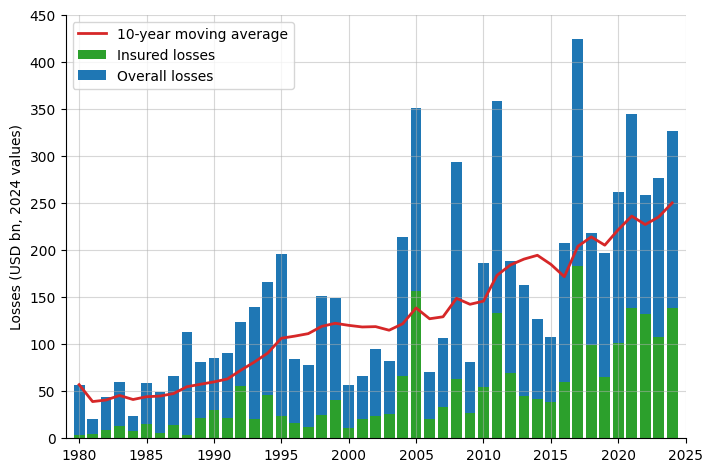

In [12]:
munich = pd.read_excel(f"{DATA_DIR}/chap12_ext_munich_re.xlsx", sheet_name="Feuil1")
year = munich["year"]
insured = munich["insured_loss"]
uninsured = munich["total_loss"] - munich["insured_loss"]
y_mean = (
    munich["total_loss"].rolling(window=11, min_periods=1).mean()
)  # trailing 10 years + current

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.bar(year, insured, color=color_green, label="Insured losses")
ax.bar(year, uninsured, bottom=insured, color=color_blue, label="Overall losses")
ax.plot(year, y_mean, "-", color=color_red, linewidth=2.0, label="10-year moving average")

ax.set_xlim(1979, 2025)
ax.set_xticks(range(1980, 2026, 5))
ax.set_ylim(0, 450)
ax.set_yticks(range(0, 451, 50))
ax.grid(True, alpha=0.5)
ax.legend(fontsize=10, loc="upper left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylabel("Losses (USD bn, 2024 values)")
plt.show()

### 5. Munich Re losses by historical sub-period

Total, insured, and uninsured losses aggregated over a set of notable
historical windows (each decade, the full 1980-2024 period, and 5 more
recent multi-year windows), with the uninsured ("protection gap") share
of total losses.


In [13]:
selected_begin = [1980, 1990, 2000, 2010, 2020, 1980, 2005, 2011, 2017, 2021, 2024]
selected_end = [1989, 1999, 2009, 2019, 2024, 2024, 2005, 2011, 2017, 2021, 2024]

rows = []
for b, e in zip(selected_begin, selected_end):
    mask = (year >= b) & (year <= e)
    total = munich.loc[mask, "total_loss"].sum()
    ins = munich.loc[mask, "insured_loss"].sum()
    uninsured_sum = total - ins
    rows.append([b, e, total, ins, uninsured_sum, 100 * uninsured_sum / total])

periods = pd.DataFrame(
    rows,
    columns=["From", "To", "Total loss", "Insured loss", "Uninsured loss", "Uninsured share (%)"],
)
display(periods.round(1))

,From,To,Total loss,Insured loss,Uninsured loss,Uninsured share (%)
0,1980,1989,574,96.1,477.9,83.3
1,1990,1999,1263,293.0,970.0,76.8
2,2000,2009,1417,448.0,969.0,68.4
3,2010,2019,2176,790.0,1386.0,63.7
4,2020,2024,1470,617.0,853.0,58.0
5,1980,2024,6900,2244.1,4655.9,67.5
6,2005,2005,351,157.0,194.0,55.3
7,2011,2011,358,133.0,225.0,62.8
8,2017,2017,424,183.0,241.0,56.8
9,2021,2021,345,138.0,207.0,60.0


### 6. EIOPA climate risk dashboard scores by country and peril

The EIOPA insurance-risk dashboard's physical-risk scores (0 = low risk)
for 31 European countries across 5 perils (coastal flood, earthquake,
river flood, wildfire, windstorm): the historical score (max across the
2022-2025 database vintages) and the current/estimated 2025 score, plus
a total-across-perils column. A `-9` sentinel marks "not applicable" (a
peril with no meaningful exposure for that country, e.g. coastal flood
for a landlocked country).


In [14]:
eiopa = pd.read_excel(f"{DATA_DIR}/chap12_ext_eiopa_dashboard.xlsx", sheet_name="Sheet1")
countries = sorted(eiopa["Country"].unique())
hazards = sorted(eiopa["Peril"].unique())

historical = pd.DataFrame(index=countries, columns=hazards, dtype=float)
current = pd.DataFrame(index=countries, columns=hazards, dtype=float)
for c in countries:
    for h in hazards:
        sub = eiopa[(eiopa["Country"] == c) & (eiopa["Peril"] == h)]
        historical.loc[c, h] = sub["Historical_score"].max()
        current.loc[c, h] = sub.loc[sub["DB_version"] == 2025, "Estimated_score"].iloc[0]

historical = historical.replace(-9, np.nan)
current = current.replace(-9, np.nan)

results = pd.concat([historical.add_prefix("Hist_"), current.add_prefix("2025_")], axis=1)
results["Total (2025)"] = current.sum(axis=1)
display(results.round(1))
print("Perils:", hazards)

,Hist_Coastal Flood,Hist_Earthquake,Hist_Flood*,Hist_Wildfire,Hist_Windstorm,2025_Coastal Flood,2025_Earthquake,2025_Flood*,2025_Wildfire,2025_Windstorm,Total (2025)
Austria,NaN,1.0,3.0,NaN,2.0,0.0,2.0,2.5,2.5,1.0,8.0
Belgium,NaN,1.5,2.5,NaN,2.0,1.0,1.0,1.5,1.0,1.5,6.0
Bulgaria,NaN,1.5,3.0,1.5,2.5,1.5,3.0,2.5,1.5,1.5,10.0
Croatia,NaN,3.5,3.0,2.5,2.0,1.5,3.0,3.0,2.5,1.0,11.0
Cyprus,NaN,1.5,NaN,1.0,2.0,1.0,2.5,1.0,2.5,1.0,8.0
Czechia,NaN,1.0,2.5,1.0,2.5,0.0,1.0,2.5,1.0,1.5,6.0
Denmark,1.0,NaN,1.0,NaN,2.0,1.0,0.0,1.0,1.0,2.0,5.0
EEA,1.0,2.5,3.0,1.5,2.0,1.0,1.0,1.5,1.0,1.0,5.5
Estonia,NaN,NaN,1.0,NaN,2.5,1.0,0.0,1.0,1.0,1.0,4.0
Finland,1.0,NaN,2.0,NaN,1.0,1.0,0.0,1.0,1.0,1.0,4.0


Perils: ['Coastal Flood', 'Earthquake', 'Flood*', 'Wildfire', 'Windstorm']
